# Heart classification — refactored analytics project

**Dataset Source:** `heart.csv` -  UCI ML Library. This notebook separates exploratory analysis from leakage-aware training. The `output` label is a recorded dataset class; this analysis is only for study purpose and `DOES NOT` establish prospective heart-attack prediction or clinical suitability.

## 1. Imports and configuration

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display
from helpers_a import (
    load_heart_data,
    summarize_data,
    identify_iqr_outliers,
    plot_target_distribution,
    plot_numeric_distributions,
    plot_numeric_by_target,
    plot_categorical_by_target,
    plot_correlation_heatmap,
    plot_correlation_strength_labels,
    plot_variable_type_counts,
    plot_category_pies,
    plot_numeric_density_by_target,
    plot_outlier_boxplots,
    plot_winsorization_histograms,
)
from helpers_b import (
    split_features_target,
    compare_models,
    tune_logistic_regression,
    evaluate_model,
    plot_model_diagnostics,
    HeartFeatureCleaner,
    show_training_winsorization,
)

DATA_PATH = "heart.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20

## 2. Load and inspect original data

In [2]:
heart_data = load_heart_data(DATA_PATH)
summary = summarize_data(heart_data)
print("Dataset shape:", summary["shape"])
print("Missing values:")
display(summary["missing_values"].to_frame("missing_count"))
print("Unique values:")
display(summary["unique_values"].to_frame("unique_count"))
display(summary["statistics"])
display(summary["target_distribution"].to_frame("count"))

Dataset shape: (303, 14)
Missing values:


,missing_count
age,0
sex,0
cp,0
trtbps,0
chol,0
fbs,0
restecg,0
thalachh,0
exng,0
oldpeak,0


Unique values:


,unique_count
age,41
sex,2
cp,4
trtbps,49
chol,152
fbs,2
restecg,3
thalachh,91
exng,2
oldpeak,40


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trtbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalachh,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exng,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


,count
output,
0,138
1,165


## 3. Exploratory analysis
These plots describe the full observed dataset; they are **not** used to fit preprocessing statistics. Any feature-selection decisions based on the target should be validated within training folds.

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


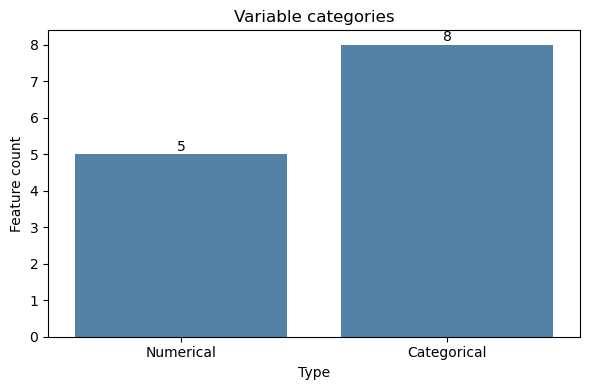

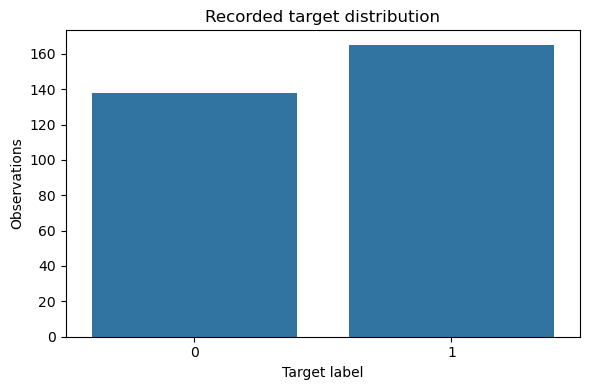

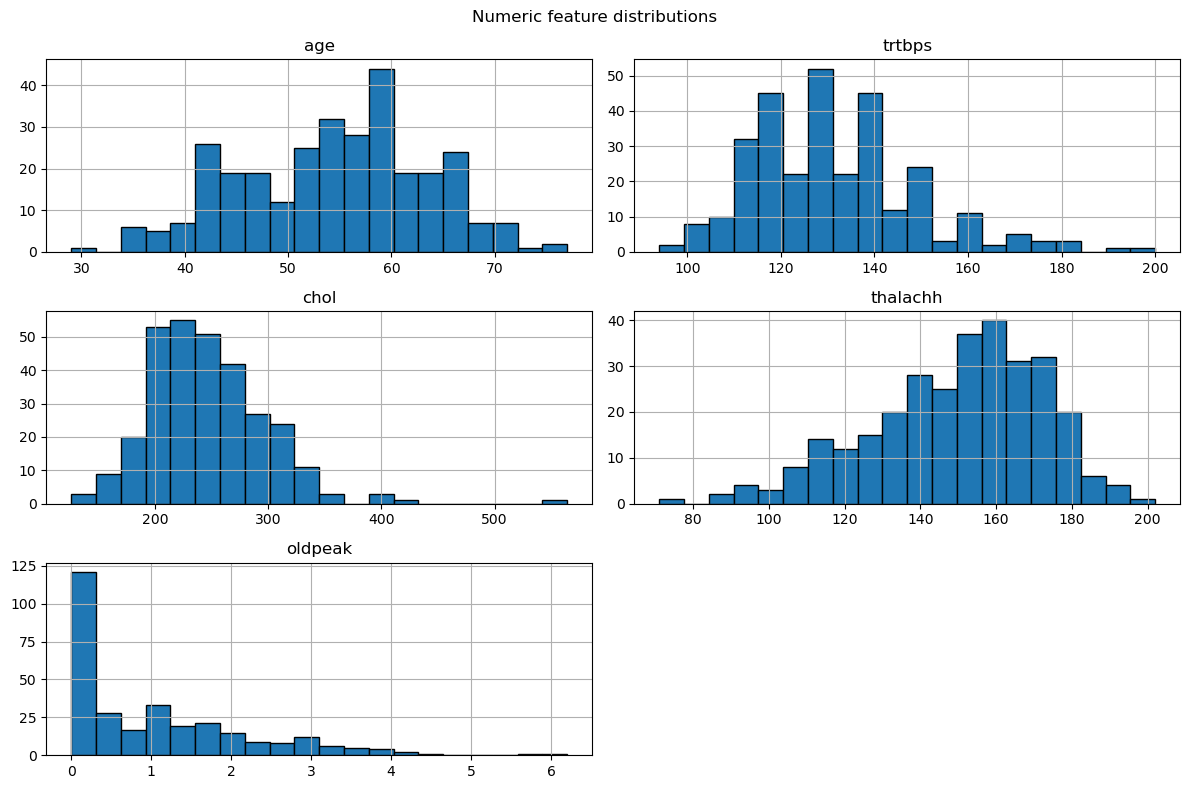

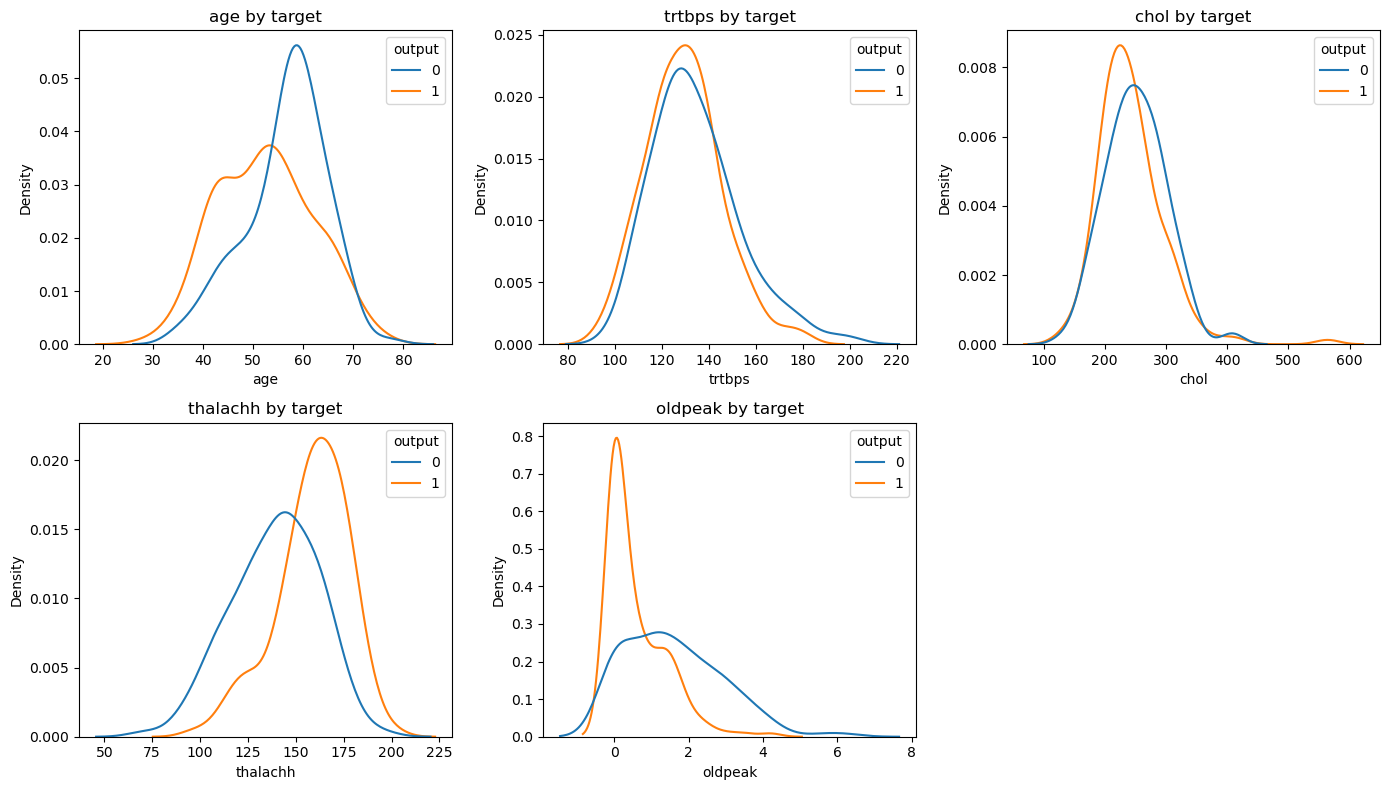

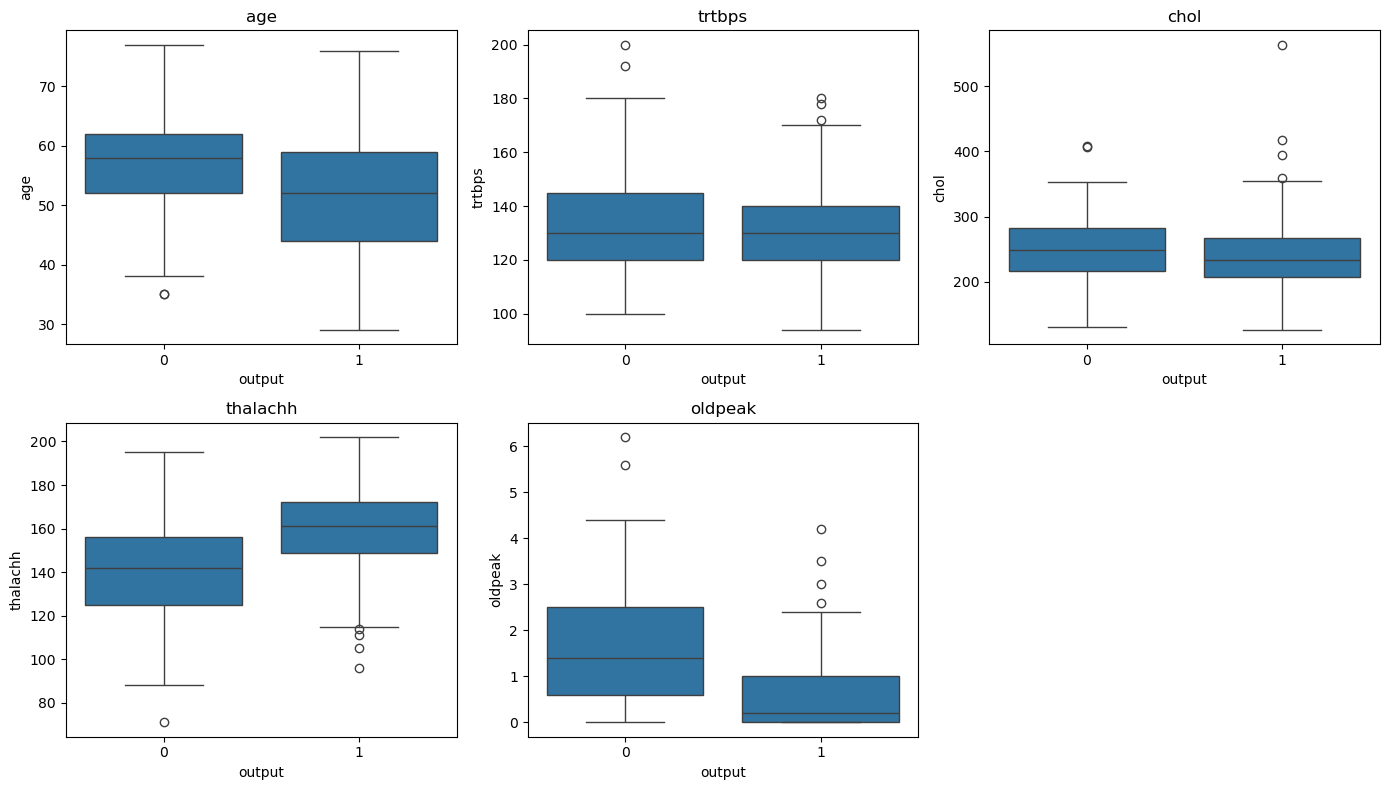

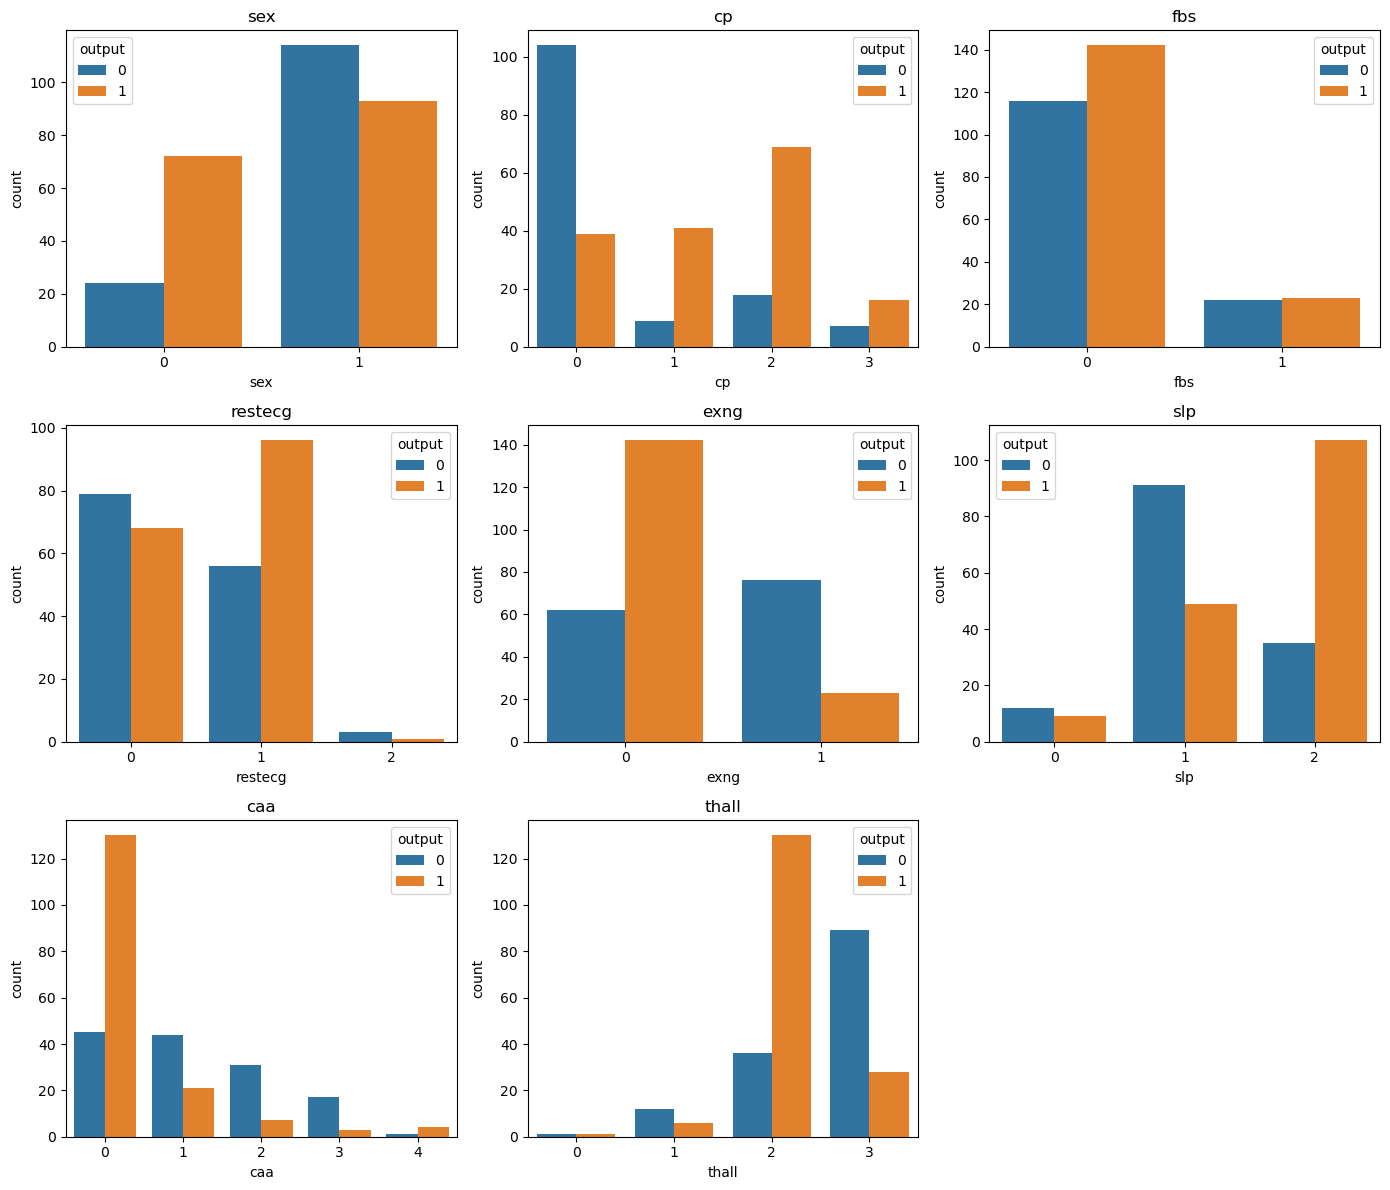

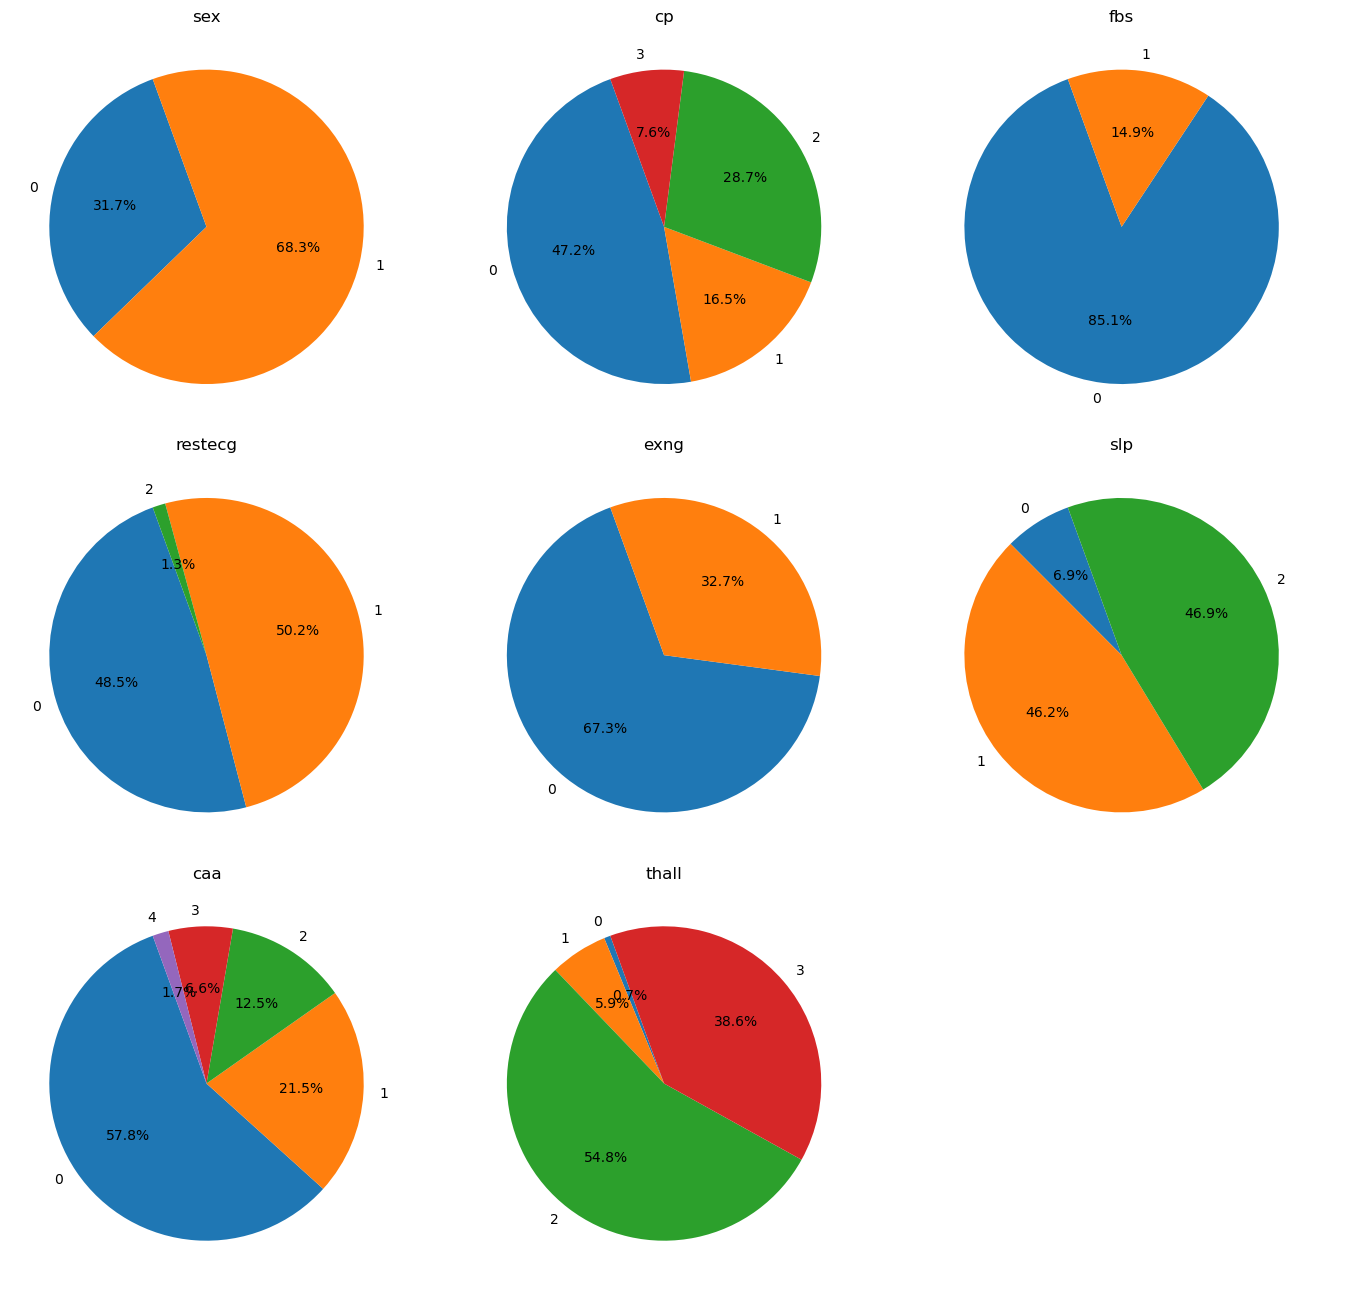

In [3]:
display(heart_data.head())
plot_variable_type_counts(heart_data)
plt.show()
plot_target_distribution(heart_data)
plt.show()
plot_numeric_distributions(heart_data)
plt.show()
plot_numeric_density_by_target(heart_data)
plt.show()
plot_numeric_by_target(heart_data)
plt.show()
plot_categorical_by_target(heart_data)
plt.show()
plot_category_pies(heart_data)
plt.show()

### Correlation heatmaps (restored)
The first heatmap displays **numeric coefficients in every cell**. The second reproduces the original notebook’s custom **NC** (absolute correlation ≤ 0.05) and **LC** (absolute correlation < 0.20) labels. The original heatmap mixed scaled numeric features with numeric-coded categorical features; Pearson correlations are invariant to positive linear scaling, so these raw-coded coefficients are equivalent for that scaling choice. Encoded category values should not be interpreted as ordinal clinical measurements.

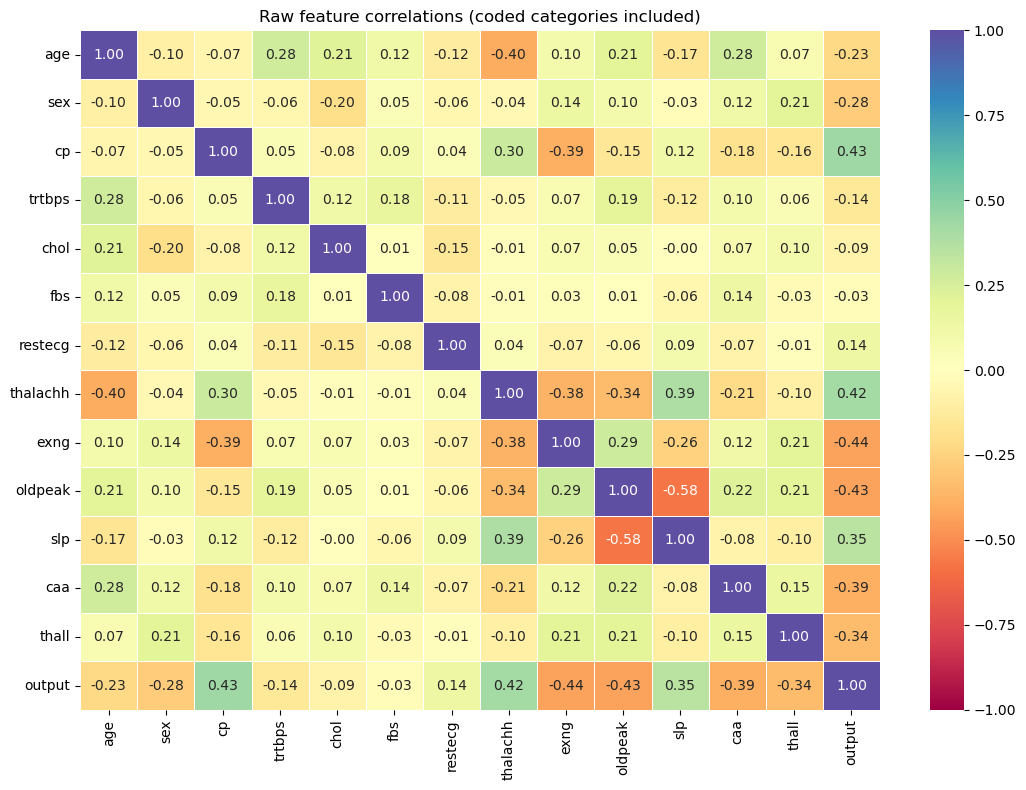

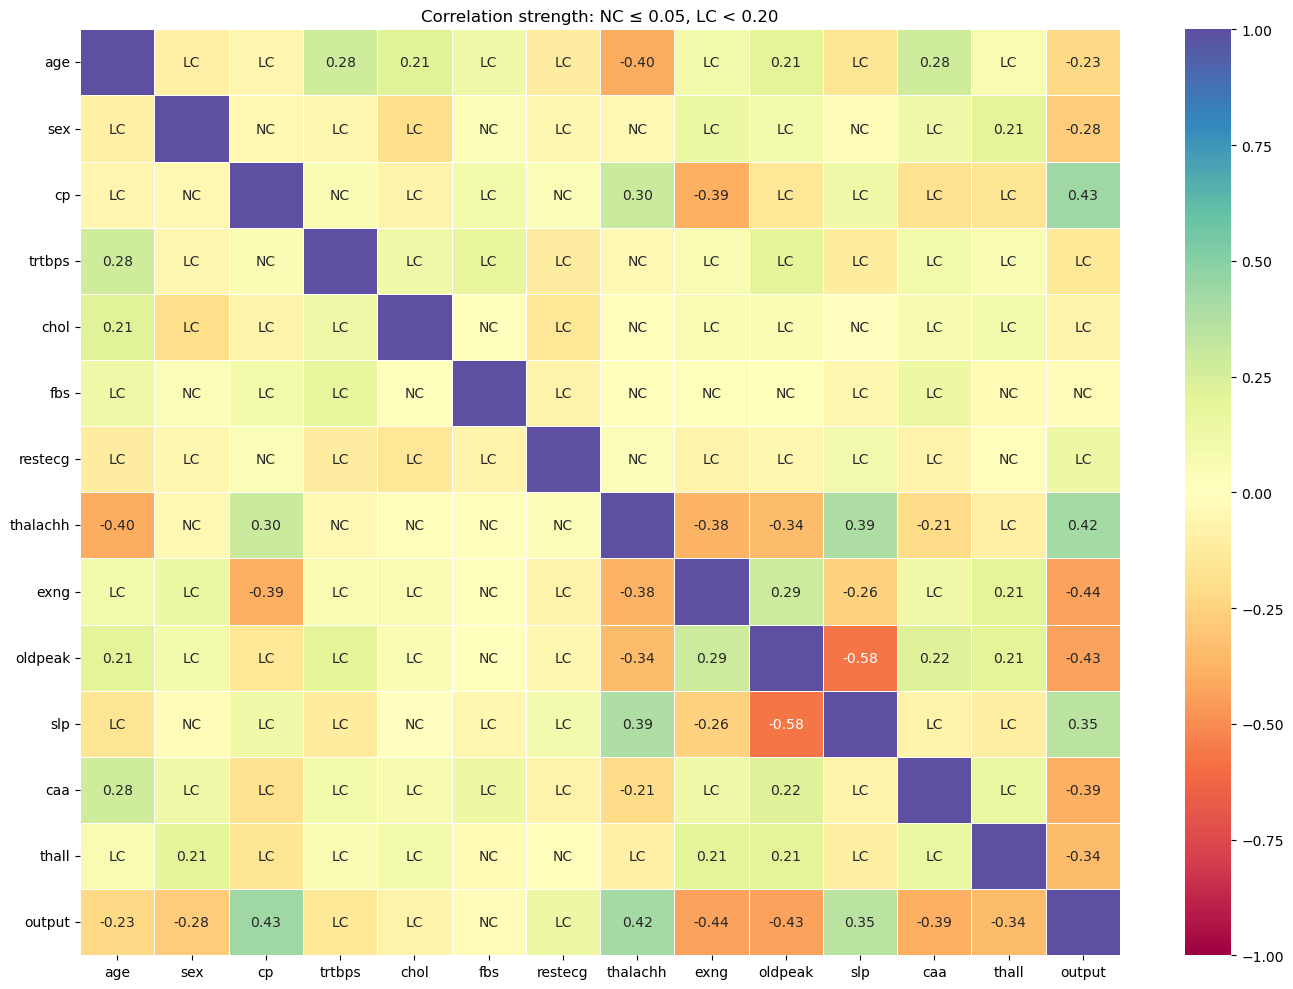

In [4]:
plot_correlation_heatmap(heart_data)
plt.show()
plot_correlation_strength_labels(heart_data)
plt.show()

## 4. Outlier review
The original notebook manually removed row 272 and winsorized blood pressure and oldpeak. Here, no observation is deleted by row number; upper-tail clipping is learned from each training fold.

In [5]:
for feature_name in ["trtbps", "thalachh", "oldpeak"]:
    outlier_rows = identify_iqr_outliers(heart_data, feature_name)
    print(f"{feature_name}: {len(outlier_rows)} IQR-flagged rows")
print("thall=0 (unknown category) rows:", int((heart_data["thall"] == 0).sum()))

trtbps: 9 IQR-flagged rows
thalachh: 1 IQR-flagged rows
oldpeak: 5 IQR-flagged rows
thall=0 (unknown category) rows: 2


## 5. Split before learned preprocessing
The original notebook dropped `fbs`, `chol`, and `restecg` based on exploratory correlation. The helper pipeline excludes them for comparability, but this is an **experimental choice**, not established optimal feature selection.

In [6]:
train_features, test_features, train_labels, test_labels = split_features_target(
    heart_data, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("Training features:", train_features.shape, "Test features:", test_features.shape)
print("Training target counts:")
display(train_labels.value_counts().sort_index())

Training features: (242, 13) Test features: (61, 13)
Training target counts:


output
0    110
1    132
Name: count, dtype: int64

### Winsorization and outlier visualizations
Your original notebook winsorized the upper tail of `trtbps` and `oldpeak`, displayed before/after boxplots and histograms, and explored square-root transformation of `oldpeak`. Here the cap is estimated from **training data only** (99th percentile by default), then applied consistently inside every model pipeline. This differs from the original manually chosen percentile cutoffs and prevents test-set leakage. `thalachh` remains an outlier-inspection feature; we do not silently delete row 272.

Training-derived upper-tail winsorization caps: {'trtbps': 180.0, 'oldpeak': 4.318000000000001}


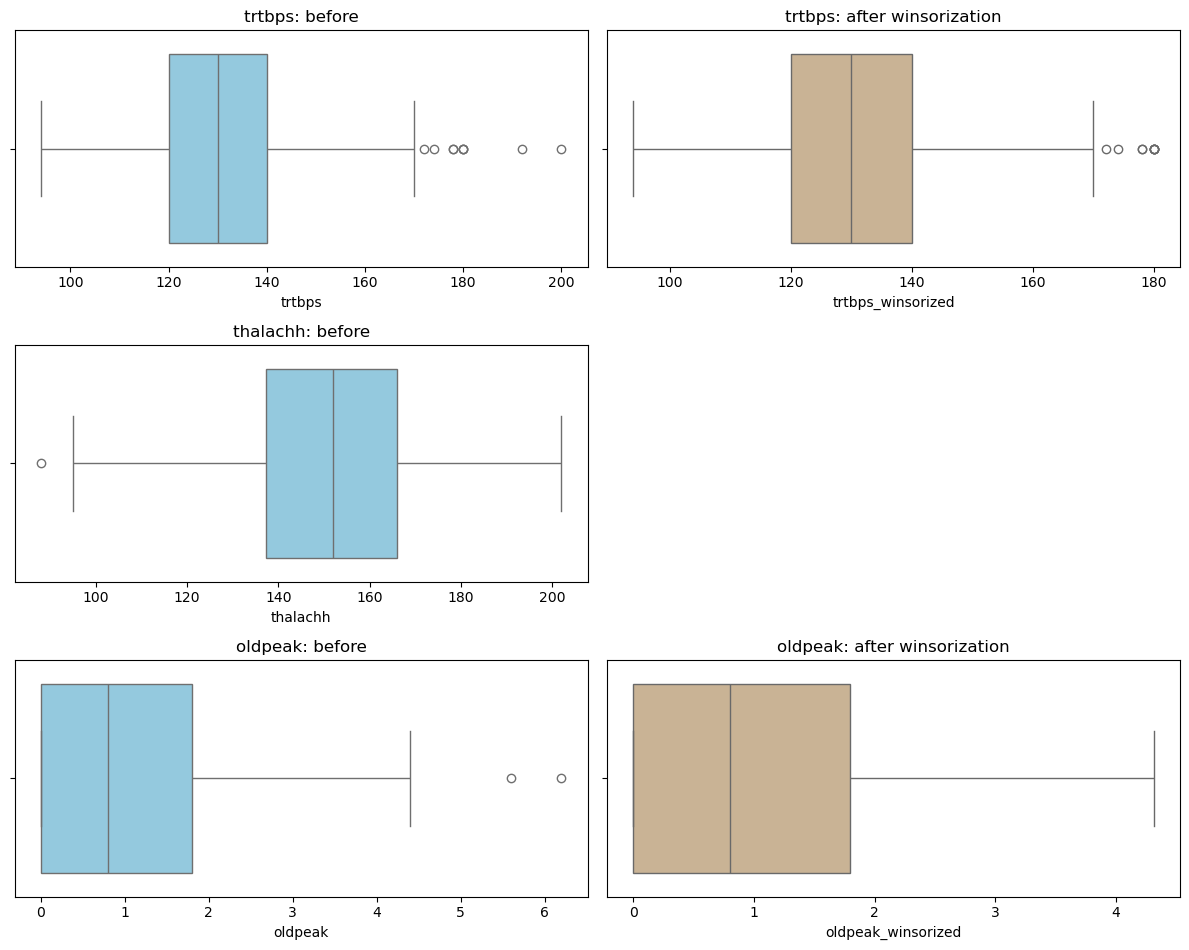

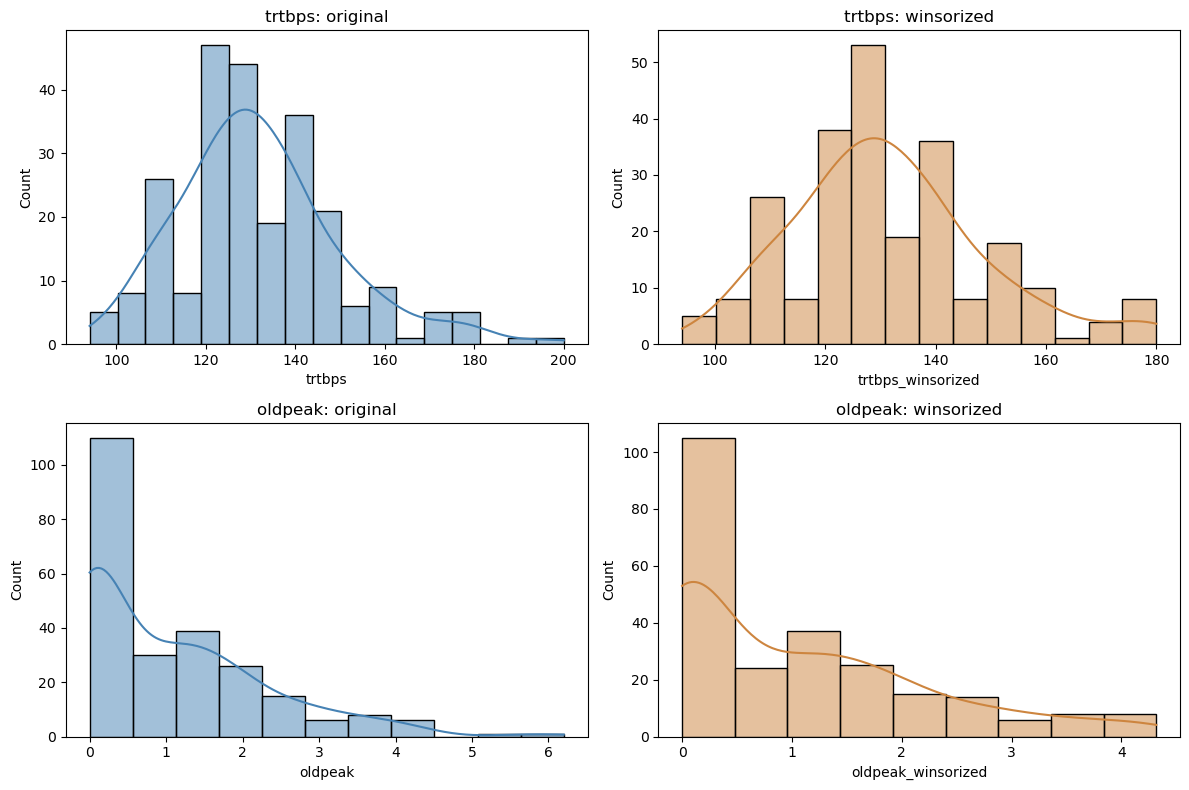

Oldpeak skewness:


,skewness
oldpeak,1.258756
oldpeak_winsorized,1.015991
oldpeak_winsorized_sqrt,0.125557


In [7]:
eda_cleaner = HeartFeatureCleaner(clip_quantile=0.99).fit(train_features)
winsorization_comparison = show_training_winsorization(train_features, eda_cleaner)
print("Training-derived upper-tail winsorization caps:", eda_cleaner.upper_bounds_)
plot_outlier_boxplots(winsorization_comparison)
plt.show()
plot_winsorization_histograms(winsorization_comparison)
plt.show()
print("Oldpeak skewness:")
display(
    winsorization_comparison[
        ["oldpeak", "oldpeak_winsorized", "oldpeak_winsorized_sqrt"]
    ]
    .skew()
    .to_frame("skewness")
)

## 6. Compare four machine-learning models
Cross-validation occurs **only on training data**. Every CV fold fits its own clipping, imputation, encoding, and scaling parameters.

In [8]:
model_comparison, fitted_models = compare_models(
    train_features,
    test_features,
    train_labels,
    test_labels,
    cv_folds=5,
    random_state=RANDOM_STATE,
)
display(model_comparison.round(3))

,model,cv_f1_mean,cv_f1_std,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.866,0.040,0.869,0.821,0.970,0.889,0.946
1,Support Vector Machine,0.850,0.059,0.836,0.780,0.970,0.865,0.936
2,Random Forest,0.836,0.053,0.820,0.762,0.970,0.853,0.932
3,Decision Tree,0.764,0.006,0.721,0.700,0.848,0.767,0.710


## 7. Tune logistic regression on training data only

In [9]:
logistic_search = tune_logistic_regression(train_features, train_labels)
print("Best parameters:", logistic_search.best_params_)
print("Best cross-validation F1:", round(logistic_search.best_score_, 3))
print("Tuned logistic holdout metrics:")
display(evaluate_model(logistic_search.best_estimator_, test_features, test_labels))

Best parameters: {'model__C': 1, 'model__l1_ratio': 0.0, 'model__solver': 'liblinear'}
Best cross-validation F1: 0.866
Tuned logistic holdout metrics:


c:\Users\santo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


{'accuracy': 0.8688524590163934,
 'precision': 0.8205128205128205,
 'recall': 0.9696969696969697,
 'f1': 0.8888888888888888,
 'roc_auc': 0.9458874458874459}

## 8. Diagnostic plots

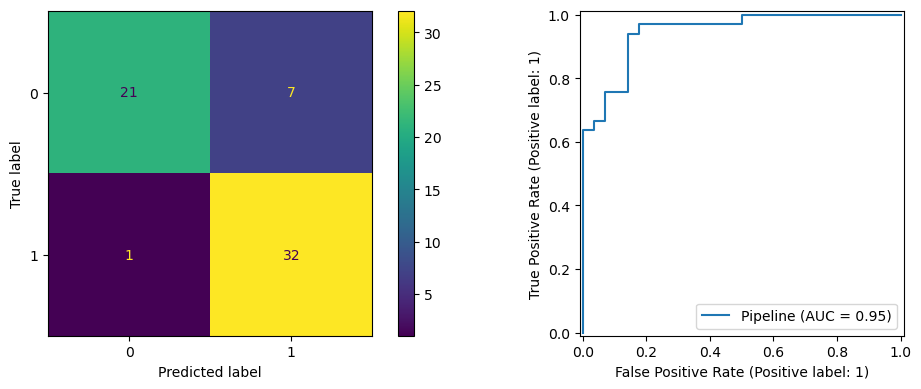

In [10]:
plot_model_diagnostics(logistic_search.best_estimator_, test_features, test_labels)
plt.show()

## 9. Study Points

1. **Problem:** Binary classification of the provided `output` label from tabular heart-related measurements.
2. **Output** ML Models, Performance metrics and their comparision.
2. **EDA:** Examined missingness, feature distributions, class balance, category frequencies, correlations, and potential outliers.
3. **Preprocessing:** Replaced invalid `thall=0` with an unknown value, imputed within training folds, clipped upper tails, applied a square-root transform to `oldpeak`, robust-scaled numeric features, and one-hot encoded categories.
4. **Models:** Compared Logistic Regression, Decision Tree, SVM, and Random Forest with stratified holdout and training-only cross-validation.
5. **Evaluation:** Reported F1, recall, precision, accuracy, and ROC-AUC, noting that false negatives matter for any potential health-related application.
6. **Limitations:** Small dataset, no external validation, and no basis for clinical deployment.

**Methodology:** No hardcoded row deletion; no full-data scaling; no test-set CV; Random Forest uses its own predictions; solver/penalty combinations are valid; no `log(0)`; fixed random seed and stratification.

**Naming examples:** `ha_df` → `heart_data`; `x` → `train_features` / `test_features`; `y` → `train_labels` / `test_labels`; `new_hadf2_usdf` → eliminated (preprocessing pipeline); `log_reg_ml_usdf_new_2` → `logistic_search.best_estimator_`; `rf_model_usdf` → `fitted_models["Random Forest"]`.

                                **Model Comparison and Final Prediction**

Multiple machine learning classification models are trained and evaluated using performance metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

The models are compared to identify the best-performing model, with particular emphasis on Recall and F1-Score to minimize false-negative predictions.

                                        **Final Output:**

The selected model is then used to predict the heart disease classification for a new patient record based on the provided clinical attributes.

Predicted classification (0 - No Heart Disease or 1 - Yes Heart Disease), along with the model's estimated probability when supported.